# Joint-likelihood bout model -- six variants

`L = -[ log p(dtheta | x) + log p(l | x, dtheta) + log p(tau | x, dtheta, l) ]`

One feature vector (turn history + stimulus + border + kinematic history), one shared body, heads
chained within the bout. Three stimulus representations x {unconstrained, containment}.

None of the lineage calibrators (vigor, artr, kin_feedback, qmap, indiv, innov_comp). The
guardrail is on in all six -- that is what keeps the fish in the dish; `contain` is a separate
thing that corrects the radial *occupancy distribution*.

In [1]:
import sys, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
# ladder artefacts are pickled on Colab under numpy 2; this env may be numpy 1
if not hasattr(np, "_core"):
    import numpy.core as _nc
    for _n in ("numpy._core", "numpy._core.multiarray", "numpy._core.numeric",
               "numpy._core.umath", "numpy._core._multiarray_umath"):
        try:
            sys.modules[_n] = __import__(_n.replace("numpy._core", "numpy.core"), fromlist=["x"])
        except Exception:
            pass
warnings.filterwarnings("ignore", category=RuntimeWarning)   # empty-bin nanmean in the profiles

import evaluate as E
import fit_MLP as M
import fit_MLP_border as MB
import fit_MLP_mix as MX
import fit_MLP_joint as JT
import diag_range_profile as DR
import diag_border_profile as DB

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110})
REAL_C = "#3C3C3C"
# six model colours -- the lineage palette has two and its plotting loops zip over it, which
# silently truncates a six-model comparison to the first two.
MC = {"j_shoal": "#1F3B8C", "j_dot": "#0F8A6A", "j_shoalr": "#B5651D",
      "jc_shoal": "#6E8ED4", "jc_dot": "#5FBFA3", "jc_shoalr": "#E0A46A"}
MODELS = ["j_shoal", "j_dot", "j_shoalr", "jc_shoal", "jc_dot", "jc_shoalr"]
NICE = {"j_shoal": "shoal", "j_dot": "dot", "j_shoalr": "shoalr",
        "jc_shoal": "shoal +contain", "jc_dot": "dot +contain", "jc_shoalr": "shoalr +contain"}
ZIP = {m: ROOT / ("ladder_jointc_results.zip" if m.startswith("jc") else "ladder_joint_results.zip")
       for m in MODELS}
print("models:", MODELS)

models: ['j_shoal', 'j_dot', 'j_shoalr', 'jc_shoal', 'jc_dot', 'jc_shoalr']


## Data and checkpoints

In [2]:
df = E.load_bouts(str(ROOT / "data" / "bouts_GsizeMotionSingle.csv"))
records = MB.build_border_records(df)          # dict: DR.real_side/gen_side need this
recs = list(records.values())                  # list: rollout()/border_profile() need this
print(f"{len(recs)} fish, {sum(r.n for r in recs)} bouts")

_TMP = ROOT / "notebooks" / "_zip_joint"

def load_ckpt(m):
    '''Extract ladder_<m>.pt from its results zip (once) and load it.'''
    _TMP.mkdir(parents=True, exist_ok=True)
    dest = _TMP / f"ladder_{m}.pt"
    if not dest.exists():
        with zipfile.ZipFile(ZIP[m]) as z:
            dest.write_bytes(z.read(f"ladder_{m}.pt"))
    return JT.load_joint(str(dest))

def load_table(which, name):
    '''`which` in {results, panel, likA}; `name` in {joint, jointc}.'''
    with zipfile.ZipFile(ROOT / f"ladder_{name}_results.zip") as z:
        import io
        return pd.read_csv(io.BytesIO(z.read(f"{which}.csv")))

MDL = {m: load_ckpt(m) for m in MODELS}
for m in MODELS:
    cf = MDL[m]._cfg_feat
    print(f"  {NICE[m]:16s} D={MDL[m]._model.body[0].in_features:3d}  stim={cf['stim_mode']:7s} "
          f"n_dist={MDL[m]._model.n_dist} n_dt={MDL[m]._model.n_dt} "
          f"contain={'yes' if isinstance(cf.get('centre_bias'), dict) else 'no'}")

15 fish, 70590 bouts
  shoal            D= 35  stim=shoal   n_dist=2 n_dt=3 contain=no
  dot              D= 23  stim=dot     n_dist=2 n_dt=3 contain=no
  shoalr           D= 30  stim=shoalr  n_dist=2 n_dt=3 contain=no
  shoal +contain   D= 35  stim=shoal   n_dist=2 n_dt=3 contain=yes
  dot +contain     D= 23  stim=dot     n_dist=2 n_dt=3 contain=yes
  shoalr +contain  D= 30  stim=shoalr  n_dist=2 n_dt=3 contain=yes


In [3]:
# ONE rollout per model, cached and reused by every figure below. The lineage notebook rolls the
# same model out twice inside a single cell; at ~30 s a pass that is the dominant cost here.
def rollout(model, rs, reps=1, seed=0):
    return [(r, model.sample(r, np.random.default_rng([seed, int(r.fish_id), rep])))
            for r in rs for rep in range(reps)]

GEN = {}
for m in MODELS:
    print(f"rolling out {NICE[m]} ...")
    GEN[m] = rollout(MDL[m], recs, reps=1, seed=0)
print("done")

rolling out shoal ...
rolling out dot ...
rolling out shoalr ...
rolling out shoal +contain ...
rolling out dot +contain ...
rolling out shoalr +contain ...
done


## 1. Metric A -- all three channels

The kin lineage reports only the turn channel, so roughly two thirds of what it fits is never
scored. These models report all three.

**Read each panel across models only.** The three are log-densities with respect to different base
measures -- nats per degree, per pixel, per second -- so their absolute levels carry no meaning
relative to each other. Lower is better in every panel (they are cross-entropies).

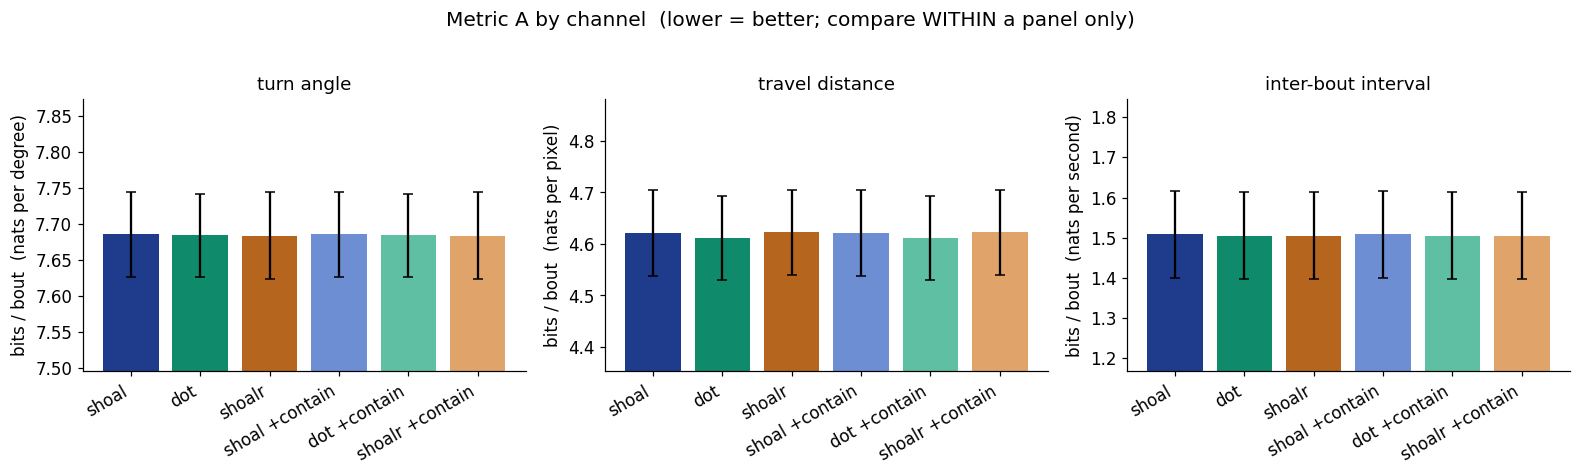

           bits_per_bout  bits_per_bout_dist  bits_per_bout_dt
m                                                             
j_shoal           7.6857              4.6212            1.5083
j_dot             7.6844              4.6121            1.5049
j_shoalr          7.6836              4.6225            1.5049
jc_shoal          7.6857              4.6212            1.5083
jc_dot            7.6844              4.6121            1.5049
jc_shoalr         7.6836              4.6225            1.5049

containment is generation-only, so the fitted nets -- and every Metric A number -- are
identical between a model and its +contain twin. Any difference here would be a bug.


In [4]:
likA = pd.concat([load_table("likA", "joint"), load_table("likA", "jointc")], ignore_index=True)
KEY = {f"mlp_joint_h128_{s}{sfx}": f"{'jc' if sfx else 'j'}_{s}"
       for s in ("shoal", "dot", "shoalr") for sfx in ("", "_contain")}
likA["m"] = likA.model.map(KEY)

CH = [("bits_per_bout", "turn angle", "bits / bout  (nats per degree)"),
      ("bits_per_bout_dist", "travel distance", "bits / bout  (nats per pixel)"),
      ("bits_per_bout_dt", "inter-bout interval", "bits / bout  (nats per second)")]
fig, ax = plt.subplots(1, 3, figsize=(14.5, 4.2))
for a, (col, title, ylab) in zip(ax, CH):
    mu = [likA.loc[likA.m == m, col].mean() for m in MODELS]
    # fish-level SEM: fish are the independent unit, bouts are not
    se = [likA.loc[likA.m == m, col].std(ddof=1) / np.sqrt(likA.m.eq(m).sum()) for m in MODELS]
    a.bar(range(6), mu, yerr=se, capsize=3,
          color=[MC[m] for m in MODELS], edgecolor="none")
    lo, hi = min(mu) - 3 * max(se), max(mu) + 3 * max(se)
    a.set_ylim(lo - 0.02 * (hi - lo), hi + 0.02 * (hi - lo))    # differences are small; zoom in
    a.set_xticks(range(6)); a.set_xticklabels([NICE[m] for m in MODELS], rotation=30, ha="right")
    a.set_title(title); a.set_ylabel(ylab)
fig.suptitle("Metric A by channel  (lower = better; compare WITHIN a panel only)", y=1.02)
fig.tight_layout(); plt.show()

print(likA.groupby("m")[[c for c, _, _ in CH]].mean().reindex(MODELS).round(4).to_string())
print("\ncontainment is generation-only, so the fitted nets -- and every Metric A number -- are")
print("identical between a model and its +contain twin. Any difference here would be a bug.")

## 2. Conditional distributions

For one fish, the three fitted densities of a single bout, and how they aggregate.

Evaluated through the model's real `joint_forward`, not a hand-rolled numpy copy of it. Each
density is conditioned on what precedes it *within the same bout*: distance sees the turn, interval
sees the turn and the distance. That chain is what the kin family lacks entirely.

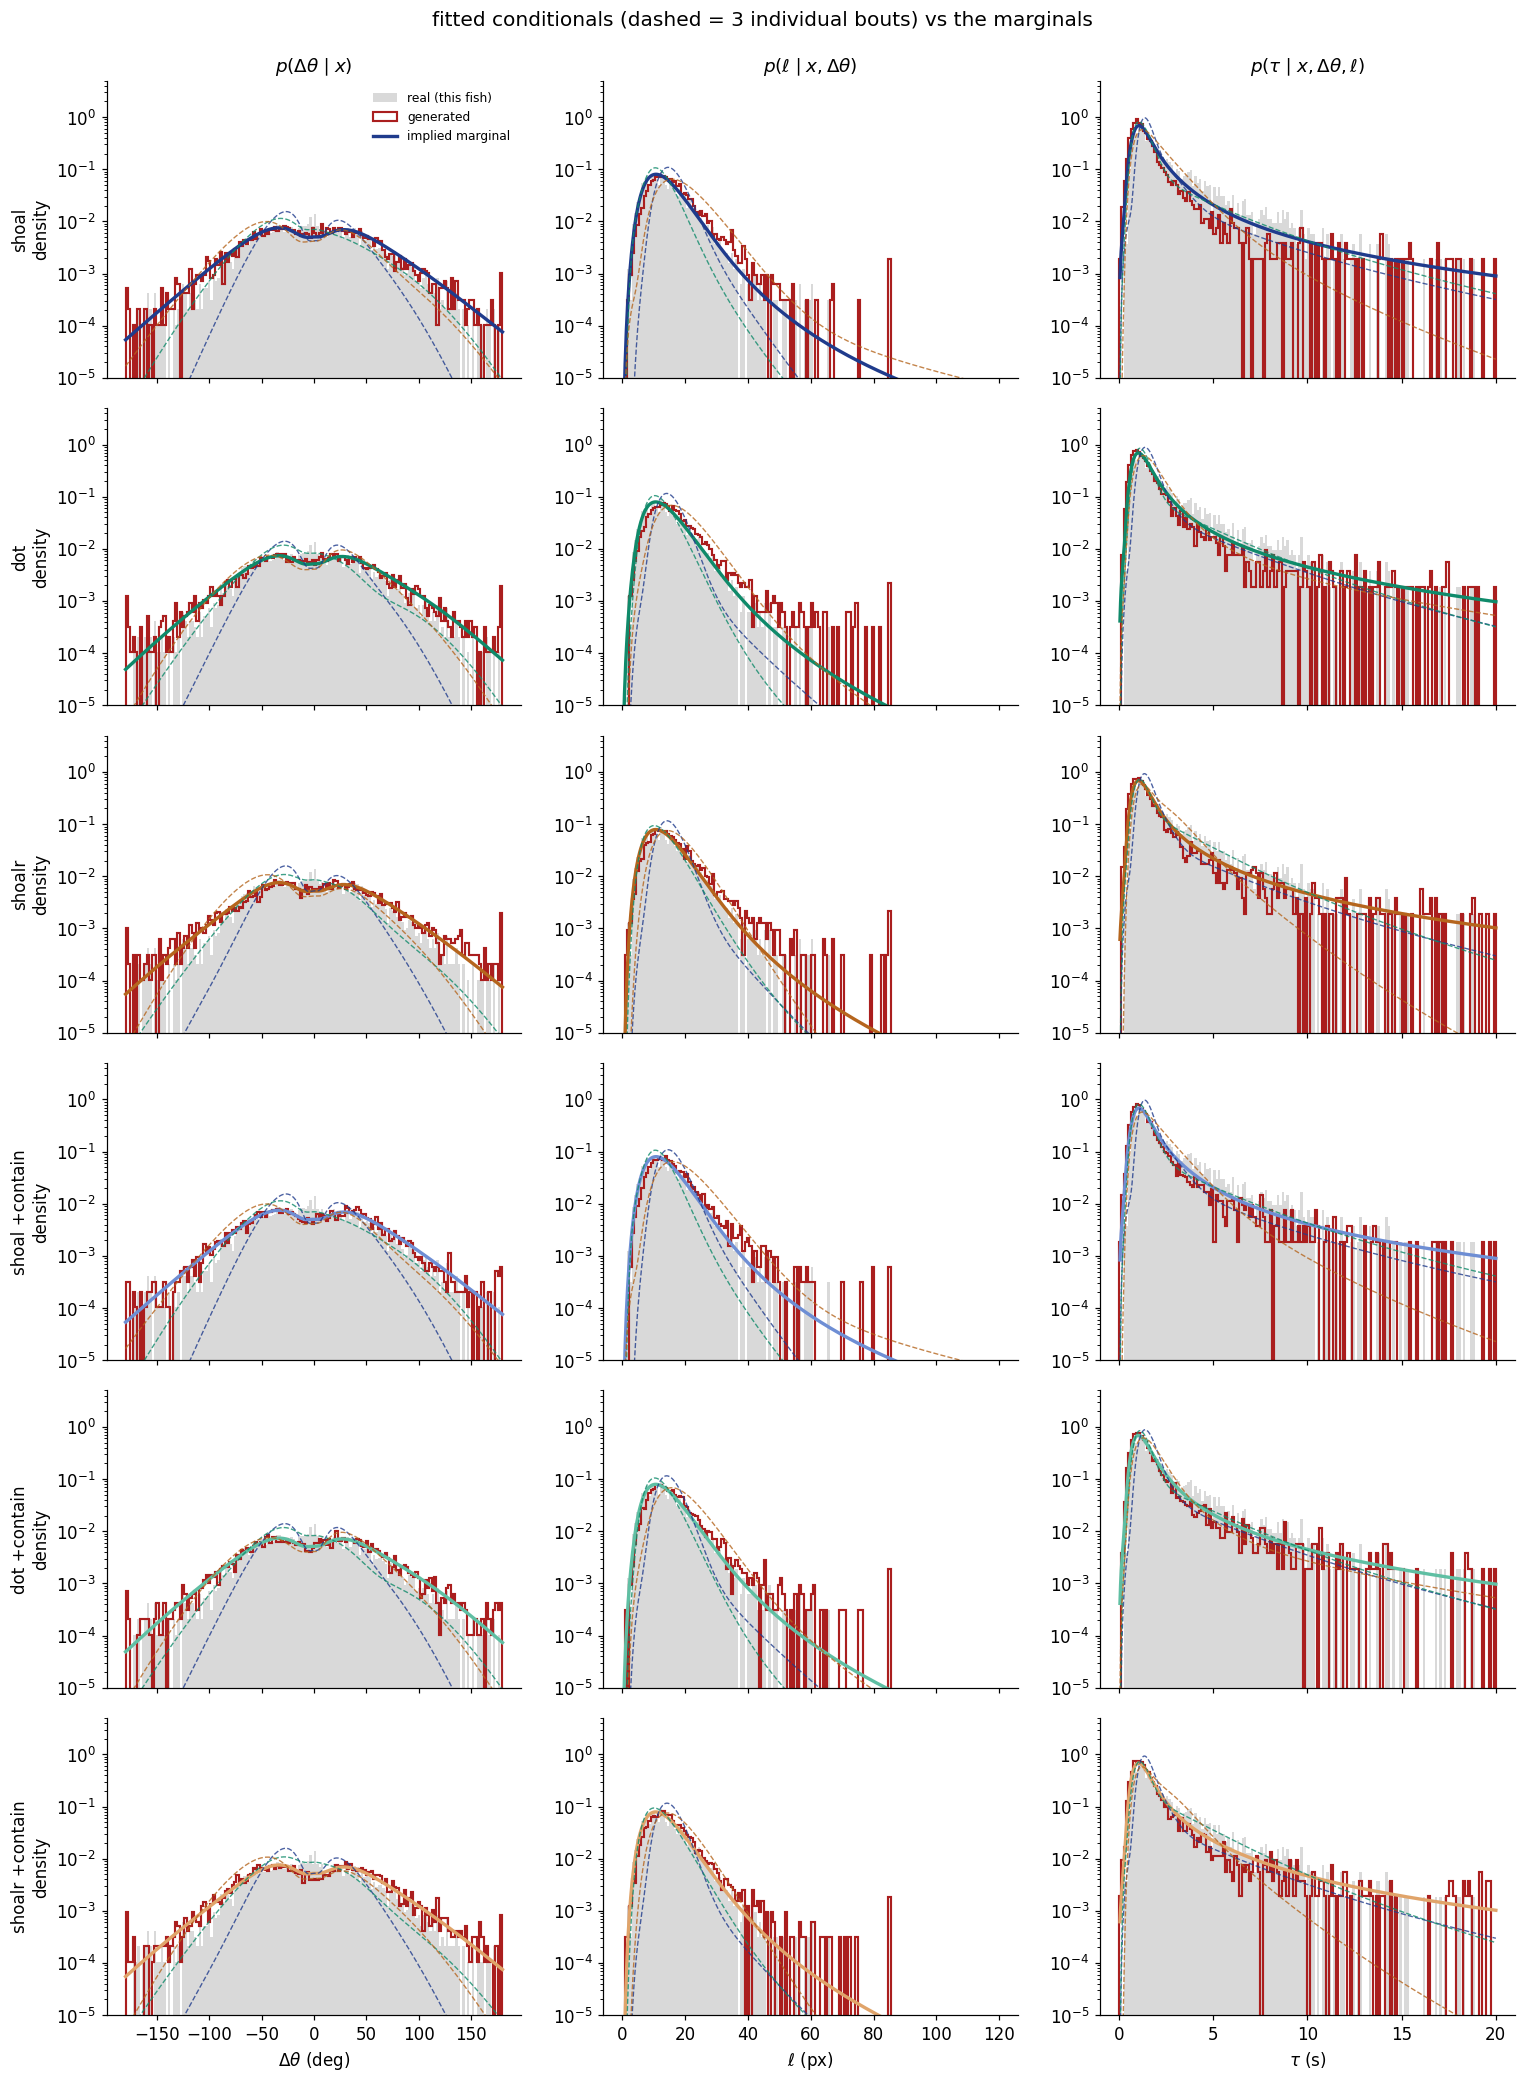

In [5]:
import torch
BOUTS = (0, 5, 17)
xs = np.linspace(-180, 180, 901); ell = np.linspace(0.5, 120, 600); tau = np.linspace(0.05, 20, 600)

def densities(m, r):
    '''(p_angle, p_dist, p_dt) evaluators + the implied marginals, from the real heads.'''
    mdl = MDL[m]; cf = mdl._cfg_feat
    X = MB.build_feature_matrix(r, cf)
    a_z, ld_c = JT._cond_cols(r.dtheta, r.distance_px, cf["dth_scale"], cf["kin_scales"])
    with torch.no_grad():
        ang, dpar, tpar = mdl._model.joint_forward(torch.tensor(X), torch.tensor(a_z),
                                                   torch.tensor(ld_c))
    logw, sF, aL1, tL1, aL2, tL2, aR1, tR1, aR2, tR2 = [np.asarray(v) for v in ang]
    w = np.exp(logw)
    from scipy.stats import norm, gamma
    def p_ang(x, i):
        p = w[i, 0] * norm.pdf(x, 0, sF[i])
        for wi, al, th, sg in ((w[i,1], aL1[i], tL1[i], -1), (w[i,2], aL2[i], tL2[i], -1),
                               (w[i,3], aR1[i], tR1[i], +1), (w[i,4], aR2[i], tR2[i], +1)):
            u = sg * x
            p = p + wi * np.where(u > 0, gamma.pdf(np.clip(u, 1e-9, None), al, scale=th), 0.0)
        return p
    def _lnmix(par):
        lw, mu, sg = [np.asarray(v) for v in par]
        ww = np.exp(lw)
        return lambda x, i: sum(ww[i, k] * np.exp(-(np.log(x) - mu[i, k])**2 / (2 * sg[i, k]**2))
                                / (x * sg[i, k] * np.sqrt(2 * np.pi)) for k in range(ww.shape[1]))
    return p_ang, _lnmix(dpar), _lnmix(tpar), len(X)

r0 = recs[0]
fig, ax = plt.subplots(6, 3, figsize=(14, 19), sharex="col")
for row, m in enumerate(MODELS):
    p_ang, p_d, p_t, n = densities(m, r0)
    g = next(gg for rr, gg in GEN[m] if rr is r0)   # FishRecord is unhashable -> match by identity
    for col, (grid, pf, real, gen, xlab, rng_) in enumerate((
            (xs, p_ang, r0.dtheta, g["dtheta"], r"$\Delta\theta$ (deg)", (-180, 180)),
            (ell, p_d, np.abs(r0.distance_px), np.abs(g["distance_px"]), r"$\ell$ (px)", (0, 120)),
            (tau, p_t, r0.dt_s, g["dt_s"], r"$\tau$ (s)", (0, 20)))):
        a = ax[row, col]
        a.hist(real, bins=160, range=rng_, density=True, color="0.85", label="real (this fish)")
        a.hist(gen, bins=160, range=rng_, density=True, histtype="step", lw=1.4,
               color="#AA1E1E", label="generated")
        a.plot(grid, np.mean([pf(grid, i) for i in range(0, n, 7)], axis=0), lw=2.2,
               color=MC[m], label="implied marginal")
        for i, c in zip(BOUTS, ("#1F3B8C", "#0F8A6A", "#B5651D")):
            a.plot(grid, pf(grid, i), lw=0.9, ls="--", color=c, alpha=0.8)
        a.set_yscale("log"); a.set_ylim(1e-5, 5)
        if row == 5:
            a.set_xlabel(xlab)
        if col == 0:
            a.set_ylabel(f"{NICE[m]}\ndensity")
        if row == 0 and col == 0:
            a.legend(fontsize=8, frameon=False)
ax[0, 0].set_title(r"$p(\Delta\theta \mid x)$")
ax[0, 1].set_title(r"$p(\ell \mid x, \Delta\theta)$")
ax[0, 2].set_title(r"$p(\tau \mid x, \Delta\theta, \ell)$")
fig.suptitle("fitted conditionals (dashed = 3 individual bouts) vs the marginals", y=0.995)
fig.tight_layout(); plt.show()

## 3. Stimulus response: the inverted U

Real fish turn toward the shoal most at intermediate range -- P(turn toward) peaks in the 70-90 px
bin and falls off both nearer and further. A model with only a monotone proximity cue cannot
express that shape. Panel B is the restoring force: where `E[dr|r]` crosses zero is the set point
the fish holds.

Computed by `diag_range_profile`, which does **not** feed the C2ST, so it is an independent check.

range profile shoal ...
range profile dot ...
range profile shoalr ...
range profile shoal +contain ...
range profile dot +contain ...
range profile shoalr +contain ...


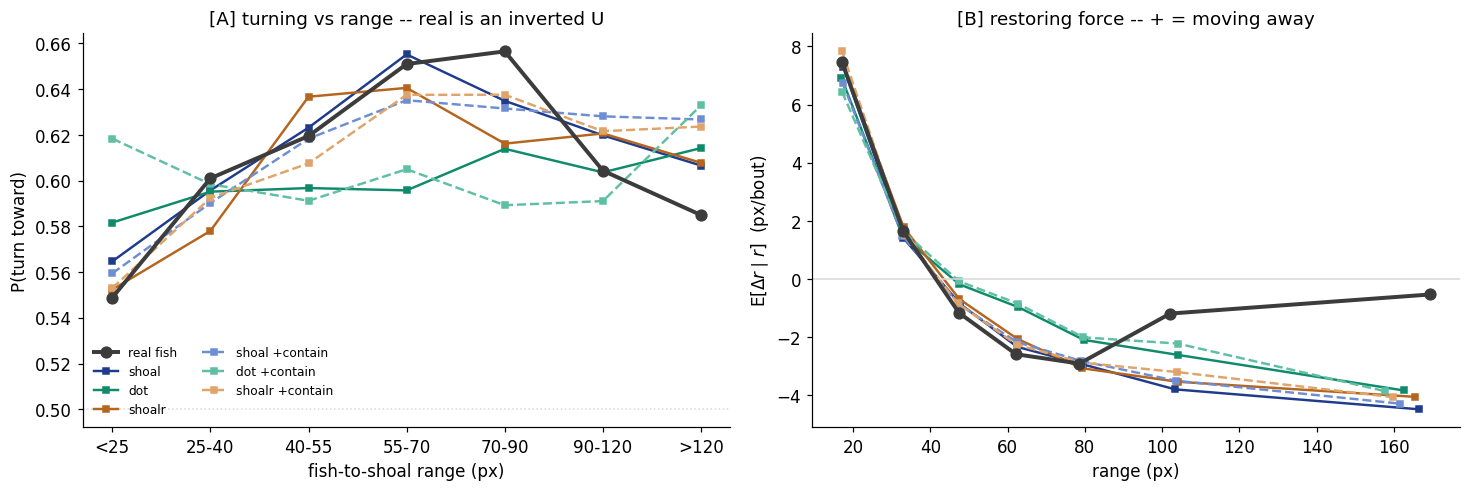

model               curvature  zero-crossing (px)
REAL                    0.090                41.4
shoal                   0.049                42.1
dot                     0.016                45.9
shoalr                  0.036                43.4
shoal +contain          0.038                42.0
dot +contain           -0.036                46.7
shoalr +contain         0.049                42.2

curvature = peak minus the mean of the two end bins; real is strongly positive.


In [6]:
RS = DR.real_side(records)
GS = {}
for m in MODELS:
    print(f"range profile {NICE[m]} ...")
    GS[m] = DR.gen_side(MDL[m], records, reps=1, seed=0)

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))
xr = np.arange(len(DR.R_LABELS))
ax[0].plot(xr, RS["toward"], "-o", lw=2.6, ms=7, color=REAL_C, label="real fish", zorder=5)
ax[0].axhline(0.5, color="0.85", ls=":", lw=1)
for m in MODELS:
    ax[0].plot(xr, GS[m]["toward"], "--s" if m.startswith("jc") else "-s", ms=4, lw=1.6,
               color=MC[m], label=NICE[m])
ax[0].set_xticks(xr); ax[0].set_xticklabels(DR.R_LABELS)
ax[0].set_xlabel("fish-to-shoal range (px)"); ax[0].set_ylabel("P(turn toward)")
ax[0].set_title("[A] turning vs range -- real is an inverted U")
ax[0].legend(fontsize=8, frameon=False, ncol=2)

ax[1].plot(RS["rmid"], RS["dr"], "-o", lw=2.6, ms=7, color=REAL_C, label="real", zorder=5)
for m in MODELS:
    ax[1].plot(GS[m]["rmid"], GS[m]["dr"], "--s" if m.startswith("jc") else "-s", ms=4, lw=1.6,
               color=MC[m], label=NICE[m])
ax[1].axhline(0, color="0.85", lw=1)
ax[1].set_xlabel("range (px)"); ax[1].set_ylabel(r"E[$\Delta r\mid r$]  (px/bout)")
ax[1].set_title("[B] restoring force -- + = moving away")
fig.tight_layout(); plt.show()

print(f"{'model':18s}{'curvature':>11s}{'zero-crossing (px)':>20s}")
print(f"{'REAL':18s}{DR._curvature(RS['toward']):11.3f}"
      f"{DR._zero_crossing(RS['dr'], RS['rmid']):20.1f}")
for m in MODELS:
    print(f"{NICE[m]:18s}{DR._curvature(GS[m]['toward']):11.3f}"
          f"{DR._zero_crossing(GS[m]['dr'], GS[m]['rmid']):20.1f}")
print("\ncurvature = peak minus the mean of the two end bins; real is strongly positive.")

## 4. Where the fish lives: radial occupancy and turning inward

Left: how often the fish turns toward the centre, by distance to the wall. Right: the stationary
radial distribution. `contain` targets the right panel directly.

**Heading is reconstructed from consecutive generated positions.** The lineage notebook passes the
*real* per-bout heading alongside *generated* positions, which computes the egocentric bearing in
the wrong frame -- so its generated and real curves are not the same estimator.

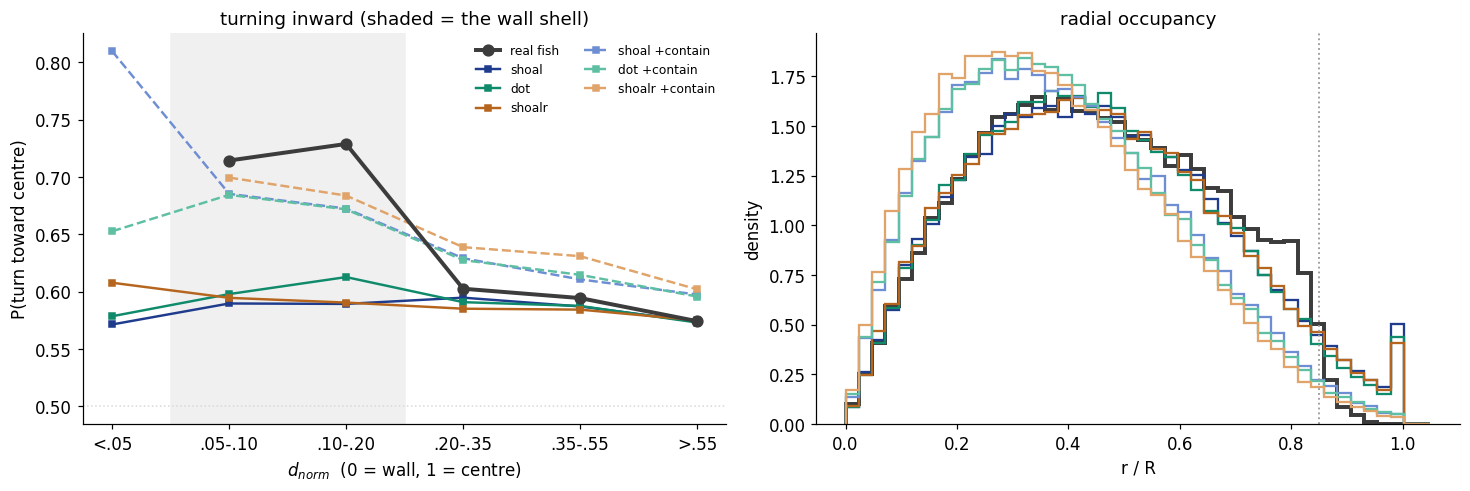

model               mean r/R  frac > 0.85  P(inward) in shell
REAL                   0.449       0.0123               0.722
shoal                  0.456       0.0491               0.590
dot                    0.451       0.0428               0.605
shoalr                 0.453       0.0458               0.593
shoal +contain         0.392       0.0174               0.679
dot +contain           0.387       0.0161               0.678
shoalr +contain        0.374       0.0129               0.692


In [7]:
def border_profile(pairs):
    '''Pool DB._profile over (record, rollout) pairs. `gen is None` -> the real side.'''
    parts = []
    for r, gph in pairs:
        if gph is None:
            x, y, dth, ori = r.x_px, r.y_px, r.dtheta, r.f_ori_rad
        else:
            x = np.asarray(gph["x_px"], float); y = np.asarray(gph["y_px"], float)
            dth = np.asarray(gph["dtheta"], float)
            # heading of a GENERATED fish comes from its own consecutive positions
            ori = np.zeros(len(x)); ori[0] = r.f_ori_rad[0]
            ori[1:] = np.arctan2(np.diff(y), np.diff(x))
        parts.append(DB._profile(np.asarray(dth, float), np.asarray(x, float),
                                 np.asarray(y, float), np.asarray(ori, float),
                                 r.dish_cx, r.dish_cy, r.dish_R))
    return DB._pool(parts, "toward")

real_tw = border_profile([(r, None) for r in recs])
gen_tw = {m: border_profile(GEN[m]) for m in MODELS}

ru_real = np.concatenate([np.hypot(r.x_px - r.dish_cx, r.y_px - r.dish_cy) / r.dish_R for r in recs])
ru_gen = {m: np.concatenate([np.hypot(g["x_px"] - r.dish_cx, g["y_px"] - r.dish_cy) / r.dish_R
                             for r, g in GEN[m]]) for m in MODELS}

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))
xb = np.arange(len(DB.B_LABELS))
ax[0].axvspan(0.5, 2.5, color="0.94", zorder=0)
ax[0].plot(xb, real_tw, "-o", lw=2.6, ms=7, color=REAL_C, label="real fish", zorder=5)
ax[0].axhline(0.5, color="0.85", ls=":", lw=1)
for m in MODELS:
    ax[0].plot(xb, gen_tw[m], "--s" if m.startswith("jc") else "-s", ms=4, lw=1.6,
               color=MC[m], label=NICE[m])
ax[0].set_xticks(xb); ax[0].set_xticklabels(DB.B_LABELS)
ax[0].set_xlabel(r"$d_{norm}$  (0 = wall, 1 = centre)"); ax[0].set_ylabel("P(turn toward centre)")
ax[0].set_title("turning inward (shaded = the wall shell)")
ax[0].legend(fontsize=8, frameon=False, ncol=2)

bins = np.linspace(0, 1.05, 45)
ax[1].hist(ru_real, bins, density=True, histtype="step", lw=2.6, color=REAL_C, label="real")
for m in MODELS:
    ax[1].hist(ru_gen[m], bins, density=True, histtype="step", lw=1.5, color=MC[m], label=NICE[m])
ax[1].axvline(0.85, color="0.6", ls=":", lw=1.2)
ax[1].set_xlabel("r / R"); ax[1].set_ylabel("density"); ax[1].set_title("radial occupancy")
fig.tight_layout(); plt.show()

print(f"{'model':18s}{'mean r/R':>10s}{'frac > 0.85':>13s}{'P(inward) in shell':>20s}")
print(f"{'REAL':18s}{ru_real.mean():10.3f}{np.mean(ru_real > 0.85):13.4f}"
      f"{np.nanmean(real_tw[1:3]):20.3f}")
for m in MODELS:
    u = ru_gen[m]
    print(f"{NICE[m]:18s}{u.mean():10.3f}{np.mean(u > 0.85):13.4f}"
          f"{np.nanmean(gen_tw[m][1:3]):20.3f}")

## 5. The containment contrast, computed correctly

The two cells ran as separate invocations, so the paired-contrast table printed inside each one
only compares within its own three rungs. The contain-vs-no-contain comparison has to be made
here -- and it *is* legitimately paired: `cross_validate_generative` keys its RNG on
`(seed, fish, rep)` with no model index, and `contain` draws no random variates, so at the same
seed both runs saw identical streams.

In [8]:
import pickle, io
def artifacts(name):
    with zipfile.ZipFile(ROOT / f"ladder_{name}_results.zip") as z:
        return pickle.load(io.BytesIO(z.read("artifacts.pkl")))

A0, A1 = artifacts("joint"), artifacts("jointc")
r0, r1 = A0["auc_traj_reps"], A1["auc_traj_reps"]
print("paired contain contrast on c2st_traj_auc (negative = containment better)\n")
print(f"{'stimulus':10s}{'no contain':>12s}{'contain':>10s}{'delta':>9s}{'paired SE':>11s}{'t':>7s}   verdict")
from scipy import stats as st
for s in ("shoal", "dot", "shoalr"):
    a = np.asarray(r0[f"mlp_joint_h128_{s}"], float)
    b = np.asarray(r1[f"mlp_joint_h128_{s}_contain"], float)
    n = min(len(a), len(b)); d = b[:n] - a[:n]
    se = float(np.std(d, ddof=1) / np.sqrt(n)); t = float(np.mean(d)) / max(se, 1e-12)
    crit = float(st.t.ppf(0.975, n - 1))
    print(f"{s:10s}{a.mean():12.4f}{b.mean():10.4f}{np.mean(d):+9.4f}{se:11.4f}{t:+7.1f}   "
          f"{'RESOLVED' if abs(t) > crit else 'within noise'}")
print(f"\nfloor (real vs real): {A0['neg_control_traj']:.3f}")

paired contain contrast on c2st_traj_auc (negative = containment better)

stimulus    no contain   contain    delta  paired SE      t   verdict
shoal           0.8688    0.8529  -0.0159     0.0028   -5.8   RESOLVED
dot             0.8738    0.8569  -0.0168     0.0039   -4.3   RESOLVED
shoalr          0.8712    0.8469  -0.0242     0.0032   -7.6   RESOLVED

floor (real vs real): 0.476


## 6. Panel summary

Everything requested in one table, per model, from the cross-validated panel -- not from the
in-sample rollouts the figures above use.

In [9]:
COLS = ["abs_dtheta_w1", "dist_w1", "dt_w1", "acf_l2",
        "following_gap", "following_gap_h", "following_gap_static", "following_gap_static_h",
        "dot_dist_bias_late", "wall_frac_gap"]
res = pd.concat([load_table("results", "joint"), load_table("results", "jointc")])
res = res.rename(columns={res.columns[0]: "model"}).set_index("model")
res.index = [KEY.get(i, i) for i in res.index]
show = ["bits_per_bout", "bits_dist", "bits_dt", "c2st_traj_auc"] + COLS
print(res.reindex(MODELS)[[c for c in show if c in res.columns]].round(4).to_string())
print("\nacf_l2 is an RMS over turn-sign autocorrelation at lags (1,2,3,4,5,8,12) -- seven")
print("log-spaced lags spanning 1..12, not every lag in that range.")

           bits_per_bout  bits_dist  bits_dt  c2st_traj_auc  abs_dtheta_w1  dist_w1   dt_w1  acf_l2  following_gap  following_gap_h  following_gap_static  following_gap_static_h  dot_dist_bias_late  wall_frac_gap
j_shoal           7.6857     4.6212   1.5083         0.8688         6.8855   2.7987  0.9723  0.0464         0.1222           0.0322                0.0560                  0.0186              6.0433         0.0628
j_dot             7.6844     4.6121   1.5049         0.8738         6.8599   2.6714  0.9112  0.0464         0.1235           0.0301                0.0576                  0.0282              4.0291         0.0527
j_shoalr          7.6836     4.6225   1.5049         0.8712         7.0934   2.8254  0.9347  0.0459         0.1259           0.0324                0.0566                  0.0209              6.6934         0.0655
jc_shoal          7.6857     4.6212   1.5083         0.8529         6.7648   2.5976  1.0096  0.0474         0.1244           0.0290                0